# 06. GBLUP на кукурузе CIMMYT (Cuevas et al., 2017)

Данные: 309 DH-линий, 3 среды (EBU, KAK, KTI), признаки Yield / ASI / PH
и готовая матрица родства G (309×309), посчитанная авторами из GBS.

Что тут не так, как у пшеницы:

- сырых маркеров нет, поэтому работаю только в GBLUP-параметризации
  (g ~ N(0, G σ²_g)) — маркерные модели тут не запустить;
- масштаб G другой (диагональ ~0.2 вместо ~1) — на прогнозы не влияет,
  масштаб поглощается σ²_g;
- в каждой среде ровно одно повторение на линию, так что фенотип — это
  просто единственная запись, без усреднения;
- у G в файле нет имён линий. Я предполагаю, что порядок строк совпадает
  с отсортированными Gid, и ниже проверяю это контролем: если перемешать
  строки/столбцы G, точность должна упасть до нуля. Если не упадёт —
  значит, где-то протечка.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

for cand in [Path.cwd(), Path.cwd().parent]:
    if (cand / "gp_models" / "__init__.py").exists():
        sys.path.insert(0, str(cand))
        PROJECT = cand
        break

import gp_models as gpm
from gp_models import data, preprocessing as pp

matplotlib.rcParams["font.family"] = ["Liberation Sans", "Arimo", "DejaVu Sans"]
matplotlib.rcParams["svg.fonttype"] = "none"
FIGDIR = PROJECT / "figures"
FIGDIR.mkdir(exist_ok=True)
%matplotlib inline


In [2]:
m = data.load_maize()
ph, G = m["pheno"], m["G"]

# фенотипы: строки = линии (в порядке G), столбцы = среды
gids = np.sort(ph["Gid"].unique())
Ymaize = {}
for env in ["EBU", "KAK", "KTI"]:
    sub = ph[ph["Env"] == env].set_index("Gid").loc[gids]
    Ymaize[env] = sub["Yield"].to_numpy()
print("линий:", len(gids), "| сред:", len(Ymaize), "| NaN:",
      sum(np.isnan(v).sum() for v in Ymaize.values()))

линий: 309 | сред: 3 | NaN: 0


In [3]:
from gp_models import gblup
print("REML h2 по средам (Yield):")
vcs = {}
for env, yv in Ymaize.items():
    vc = pp.reml_variance_components(yv, G)
    vcs[env] = vc
    print(f"  {env}: h2 = {vc['h2']:.3f}  (s2g={vc['sigma2_g']:.3f}, s2e={vc['sigma2_e']:.3f})")

REML h2 по средам (Yield):
  EBU: h2 = 0.829  (s2g=2.770, s2e=0.572)
  KAK: h2 = 0.825  (s2g=1.559, s2e=0.330)
  KTI: h2 = 0.698  (s2g=1.748, s2e=0.755)


In [4]:
from gp_models import cv
res_m, res_perm = {}, {}
rng = np.random.default_rng(0)
perm = rng.permutation(G.shape[0])
Gperm = G[np.ix_(perm, perm)]          # контроль: разрушенное выравнивание
for env, yv in Ymaize.items():
    res_m[env] = cv.cv_gblup(yv, G, n_reps=50, seed=1)
    res_perm[env] = cv.cv_gblup(yv, Gperm, n_reps=50, seed=1)
    print(f"{env}: r = {res_m[env]['r'].mean():.3f} +- {res_m[env]['r'].std():.3f} "
          f"| контроль (перемеш. G): r = {res_perm[env]['r'].mean():.3f}")

EBU: r = 0.269 +- 0.091 | контроль (перемеш. G): r = -0.070


KAK: r = 0.335 +- 0.097 | контроль (перемеш. G): r = 0.011


KTI: r = 0.223 +- 0.077 | контроль (перемеш. G): r = 0.009


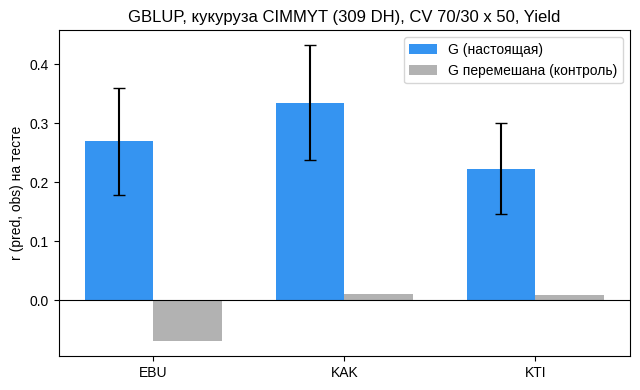

In [5]:
fig, ax = plt.subplots(figsize=(6.5, 4))
xpos = np.arange(3)
means = [res_m[e]["r"].mean() for e in Ymaize]
sds = [res_m[e]["r"].std() for e in Ymaize]
ctrl = [res_perm[e]["r"].mean() for e in Ymaize]
ax.bar(xpos - 0.18, means, 0.36, yerr=sds, capsize=4, color="#0279EE", alpha=0.8, label="G (настоящая)")
ax.bar(xpos + 0.18, ctrl, 0.36, color="grey", alpha=0.6, label="G перемешана (контроль)")
ax.axhline(0, color="k", lw=0.8)
ax.set_xticks(xpos, list(Ymaize.keys()))
ax.set_ylabel("r (pred, obs) на тесте")
ax.set_title("GBLUP, кукуруза CIMMYT (309 DH), CV 70/30 x 50, Yield")
ax.legend()
plt.tight_layout()
plt.savefig(FIGDIR / "maize_gblup_cv.png", dpi=150)
plt.savefig(FIGDIR / "maize_gblup_cv.svg")
plt.show()

## Что получилось

- Точность r ≈ 0.22–0.34 по средам — ниже, чем 0.4–0.6 у Crossa et al.
  (2013), и это объяснимо: там были тесткроссы со скорректированными
  средними по нескольким средам, а тут одна запись на линию в одной среде
  (шумные фенотипы) и маленький train (~216 линий). Cuevas et al. (2017)
  добирают точность за счёт G×E-моделей, которые объединяют среды, — у
  меня каждая среда считается отдельно.
- Контроль с перемешанной G даёт r ≈ 0 — значит, выравнивание
  генотип↔фенотип правильное, и прогноз держится именно на родстве.
- Ещё нюанс: h², которую печатает REML (0.7–0.8), посчитана в масштабе
  этой G. С поправкой на диагональ (~0.2) эффективная наследуемость
  заметно ниже (~0.3–0.5), что лучше согласуется с увиденной точностью.
- Что можно добавить дальше: многопризнаковый GBLUP (Yield+ASI+PH),
  G×E-ядра как у Cuevas et al., RKHS с гауссовым ядром на этой же G.